
# 4. Customer Churn Prediction

## 4.1 Problem Definition

Customer churn prediction is a supervised machine learning problem.

Our goal is to predict whether a customer will make a purchase during the next 90 days.

We will define the target variable as follows:

- 0: The customer makes at least one purchase.
- 1: The customer makes no purchases.

We will use 365 days of customer history to create features.

The next 90 days will be used to define the target.

This definition measures customer inactivity, not permanent customer loss.

We will use time-based validation to prevent data leakage.


In [37]:
from pathlib import Path
import sys
from sqlalchemy import text
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import product
import joblib
import json

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

import optuna
import shap
from scipy.sparse import issparse


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.database import get_engine

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

engine = get_engine()

In [2]:
# Define time periods
SNAPSHOT_DAY = 622
OBSERVATION_DAYS = 365
TARGET_DAYS = 90

OBSERVATION_START = SNAPSHOT_DAY - OBSERVATION_DAYS
TARGET_END = SNAPSHOT_DAY + TARGET_DAYS - 1

In [3]:
# Load positive-value baskets
query = text("""
    SELECT
        household_key,
        BASKET_ID,
        MIN(`DAY`) AS basket_day,
        SUM(SALES_VALUE) AS basket_sales
    FROM raw_transaction_data
    WHERE `DAY` <= :target_end
    GROUP BY household_key, BASKET_ID
    HAVING SUM(SALES_VALUE) > 0
""")

with engine.connect() as connection:
    baskets_df = pd.read_sql_query(
        query,
        con=connection,
        params={"target_end": TARGET_END},
    )

baskets_df["basket_sales"] = pd.to_numeric(
    baskets_df["basket_sales"]
)

print("Basket Dataset Shape:", baskets_df.shape)

display(baskets_df.head())

Basket Dataset Shape: (275542, 4)


,household_key,BASKET_ID,basket_day,basket_sales
0,2375,26984851472,1,5.91
1,2375,26984851516,1,12.43
2,1364,26984896261,1,11.37
3,1130,26984905972,1,2.55
4,1173,26984945254,1,3.53


In [4]:
# 1. Select customers with purchase history before snapshot
eligible_customers = (
    baskets_df.loc[
        baskets_df["basket_day"] < SNAPSHOT_DAY,
        ["household_key"]
    ]
    .drop_duplicates()
)

# 2. Select purchases during the target period
future_baskets = baskets_df.loc[
    baskets_df["basket_day"].between(
        SNAPSHOT_DAY,
        TARGET_END
    )
].copy()

# 3. Calculate future purchase days per customer
future_activity = (
    future_baskets
    .groupby("household_key", as_index=False)
    .agg(
        future_purchase_days=("basket_day", "nunique")
    )
)

# 4. Keep all eligible customers
target_df = eligible_customers.merge(
    future_activity,
    on="household_key",
    how="left",
    validate="one_to_one",
)

# 5. Replace missing future activity with zero
target_df["future_purchase_days"] = (
    target_df["future_purchase_days"]
    .fillna(0)
    .astype(int)
)

# 6. Create binary churn target
target_df["churn_90d"] = (
    target_df["future_purchase_days"]
    .eq(0)
    .astype(int)
)

# 7. Validate the dataset
assert target_df["household_key"].is_unique
assert target_df["churn_90d"].isin([0, 1]).all()

print("Eligible Customers:", len(target_df))

display(target_df.head(10))

Eligible Customers: 2499


,household_key,future_purchase_days,churn_90d
0,2375,16,0
1,1364,16,0
2,1130,33,0
3,1173,1,0
4,98,47,0
5,1172,25,0
6,1060,3,0
7,1351,8,0
8,212,7,0
9,2052,0,1


In [5]:
# Calculate target distribution
target_distribution = (
    target_df["churn_90d"]
    .value_counts()
    .sort_index()
)

# Calculate target percentages
target_percentage = (
    target_df["churn_90d"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("TARGET DISTRIBUTION")
display(target_distribution)

print("\nTARGET PERCENTAGE")
display(target_percentage.round(2))

# Calculate churn rate
churn_rate = target_df["churn_90d"].mean() * 100

print(f"\n90-Day Inactivity Rate: {churn_rate:.2f}%")

TARGET DISTRIBUTION


churn_90d
0    2325
1     174
Name: count, dtype: int64


TARGET PERCENTAGE


churn_90d
0   93.04
1    6.96
Name: proportion, dtype: float64


90-Day Inactivity Rate: 6.96%



## 4.3 Customer Feature Engineering

We will create customer-level features from historical purchase data.

Our features will describe customer activity, spending, and recent shopping behavior.

We will compare purchase frequency during two 30-day periods to measure changes in customer activity.

All features must use data before snapshot day 622.

We will also keep customers with no purchases during the observation window.

Our final dataset will contain one row per customer and a binary churn target.


In [6]:
# 1. Select historical purchases only
history_df = baskets_df.loc[
    baskets_df["basket_day"] < SNAPSHOT_DAY
].copy()

# 2. Select the observation window
history_365 = history_df.loc[
    history_df["basket_day"].between(
        OBSERVATION_START,
        SNAPSHOT_DAY - 1
    )
].copy()

# 3. Create customer-level features
customer_history = (
    history_365
    .groupby("household_key", as_index=False)
    .agg(
        purchase_frequency=("BASKET_ID", "nunique"),
        total_spending=("basket_sales", "sum"),
        avg_basket_value=("basket_sales", "mean"),
        active_days=("basket_day", "nunique"),
    )
)

# 4. Calculate the last historical purchase day
last_purchases = (
    history_df
    .groupby("household_key", as_index=False)
    .agg(
        last_purchase_day=("basket_day", "max")
    )
)

# 5. Count baskets in the last 30 days
recent_30d = (
    history_365.loc[
        history_365["basket_day"].between(
            SNAPSHOT_DAY - 30,
            SNAPSHOT_DAY - 1
        )
    ]
    .groupby("household_key", as_index=False)
    .agg(
        baskets_last_30d=("BASKET_ID", "nunique")
    )
)

# 6. Count baskets in the previous 30 days
previous_30d = (
    history_365.loc[
        history_365["basket_day"].between(
            SNAPSHOT_DAY - 60,
            SNAPSHOT_DAY - 31
        )
    ]
    .groupby("household_key", as_index=False)
    .agg(
        baskets_prev_30d=("BASKET_ID", "nunique")
    )
)

# 7. Merge all customer features
feature_df = (
    eligible_customers
    .merge(
        customer_history,
        on="household_key",
        how="left",
        validate="one_to_one"
    )
    .merge(
        last_purchases,
        on="household_key",
        how="left",
        validate="one_to_one"
    )
    .merge(
        recent_30d,
        on="household_key",
        how="left",
        validate="one_to_one"
    )
    .merge(
        previous_30d,
        on="household_key",
        how="left",
        validate="one_to_one"
    )
)

# 8. Identify customers with recent purchase history
feature_df["has_purchase_365d"] = (
    feature_df["purchase_frequency"].notna().astype(int)
)

# 9. Fill missing activity metrics
activity_columns = [
    "purchase_frequency",
    "total_spending",
    "avg_basket_value",
    "active_days",
    "baskets_last_30d",
    "baskets_prev_30d",
]

feature_df[activity_columns] = (
    feature_df[activity_columns].fillna(0)
)

# 10. Calculate recency
feature_df["recency"] = (
    SNAPSHOT_DAY - feature_df["last_purchase_day"]
)

# 11. Calculate purchase trend
feature_df["purchase_trend_30d"] = (
    feature_df["baskets_last_30d"]
    - feature_df["baskets_prev_30d"]
)

# 12. Remove the temporary column
feature_df = feature_df.drop(
    columns="last_purchase_day"
)

print("Feature Dataset Shape:", feature_df.shape)

display(feature_df.head())

Feature Dataset Shape: (2499, 10)


,household_key,purchase_frequency,total_spending,avg_basket_value,active_days,baskets_last_30d,baskets_prev_30d,has_purchase_365d,recency,purchase_trend_30d
0,2375,88.00,"2,130.00",24.20,73.00,9.00,12.00,1,1,-3.00
1,1364,75.00,"1,125.04",15.00,73.00,6.00,10.00,1,5,-4.00
2,1130,177.00,"2,864.55",16.18,125.00,15.00,10.00,1,1,5.00
3,1173,19.00,348.14,18.32,16.00,1.00,0.00,1,17,1.00
4,98,107.00,"1,555.33",14.54,80.00,28.00,22.00,1,1,6.00



## 4.4 Feature and Target Integration

We will combine historical customer features with the churn target.

Each row will represent one customer.

The dataset will contain:
- Customer ID
- Historical purchasing features
- Churn target (0 or 1)

We will check missing values, duplicate customers, and target distribution.

Future purchase information will not be included as a model feature.


In [7]:
# Merge customer features with the target
model_df = feature_df.merge(
    target_df[
        ["household_key", "churn_90d"]
    ],
    on="household_key",
    how="inner",
    validate="one_to_one",
)

# Validate the final dataset
assert len(model_df) == len(target_df)
assert model_df["household_key"].is_unique
assert model_df.notna().all().all()
assert model_df["churn_90d"].isin([0, 1]).all()

# Check for target leakage
assert "future_purchase_days" not in model_df.columns

print("Model Dataset Shape:", model_df.shape)

print("\nMissing Values:")
display(model_df.isna().sum())

print("\nTarget Distribution:")
display(model_df["churn_90d"].value_counts())

display(model_df.head())


Model Dataset Shape: (2499, 11)

Missing Values:


household_key         0
purchase_frequency    0
total_spending        0
avg_basket_value      0
active_days           0
baskets_last_30d      0
baskets_prev_30d      0
has_purchase_365d     0
recency               0
purchase_trend_30d    0
churn_90d             0
dtype: int64


Target Distribution:


churn_90d
0    2325
1     174
Name: count, dtype: int64

,household_key,purchase_frequency,total_spending,avg_basket_value,active_days,baskets_last_30d,baskets_prev_30d,has_purchase_365d,recency,purchase_trend_30d,churn_90d
0,2375,88.00,"2,130.00",24.20,73.00,9.00,12.00,1,1,-3.00,0
1,1364,75.00,"1,125.04",15.00,73.00,6.00,10.00,1,5,-4.00,0
2,1130,177.00,"2,864.55",16.18,125.00,15.00,10.00,1,1,5.00,0
3,1173,19.00,348.14,18.32,16.00,1.00,0.00,1,17,1.00,0
4,98,107.00,"1,555.33",14.54,80.00,28.00,22.00,1,1,6.00,0



## 4.5 Feature Analysis by Churn Status

We will compare purchasing behavior between active and inactive customers.

We will use median values because our customer features have skewed distributions.

Our goal is to identify possible relationships between historical customer behavior and future inactivity.

These relationships do not prove causation.


In [8]:
# Select important behavioral features
analysis_features = [
    "purchase_frequency",
    "total_spending",
    "avg_basket_value",
    "recency",
    "baskets_last_30d",
    "baskets_prev_30d",
    "purchase_trend_30d",
]

# Compare median values by target class
churn_feature_summary = (
    model_df
    .groupby("churn_90d")[analysis_features]
    .median()
    .T
)

churn_feature_summary.columns = [
    "Active (0)",
    "Inactive (1)",
]

display(churn_feature_summary.round(2))

,Active (0),Inactive (1)
purchase_frequency,46.00,8.00
total_spending,"1,287.26",195.12
avg_basket_value,27.08,20.59
recency,6.00,65.50
baskets_last_30d,4.00,0.00
baskets_prev_30d,4.00,0.00
purchase_trend_30d,0.00,0.00



## 4.6 Time-Based Dataset Preparation

We will create training, validation, and test datasets using different snapshot dates.

Each snapshot will use:
- 365 days of recent purchase history
- All earlier purchases to calculate Recency
- 90 future days to create the churn target

We will create a reusable Python function for this process.

The training dataset will contain several historical snapshots.

We will use the validation dataset for model selection and the final test dataset for the last performance evaluation.


In [9]:
def build_snapshot_dataset(
    baskets: pd.DataFrame,
    snapshot_day: int,
    observation_days: int = 365,
    target_days: int = 90,
) -> pd.DataFrame:
    """Create customer features and churn targets for a snapshot."""

    observation_start = snapshot_day - observation_days
    target_end = snapshot_day + target_days - 1

    if observation_start < 1 or target_end > baskets["basket_day"].max():
        raise ValueError("Snapshot is outside the available data.")

    # 1. Separate historical purchases
    history = baskets.loc[
        baskets["basket_day"] < snapshot_day
    ]

    recent_history = history.loc[
        history["basket_day"] >= observation_start
    ]

    # 2. Select eligible customers
    customers = history[
        ["household_key"]
    ].drop_duplicates()

    # 3. Calculate customer activity features
    customer_stats = (
        recent_history
        .groupby("household_key", as_index=False)
        .agg(
            purchase_frequency=("BASKET_ID", "nunique"),
            total_spending=("basket_sales", "sum"),
            avg_basket_value=("basket_sales", "mean"),
            active_days=("basket_day", "nunique"),
        )
    )

    # 4. Find the last historical purchase
    last_purchase = (
        history
        .groupby("household_key", as_index=False)
        .agg(last_purchase_day=("basket_day", "max"))
    )

    # 5. Calculate activity in the last 30 days
    last_30 = (
        recent_history.loc[
            recent_history["basket_day"] >= snapshot_day - 30
        ]
        .groupby("household_key")["BASKET_ID"]
        .nunique()
        .rename("baskets_last_30d")
        .reset_index()
    )

    # 6. Calculate activity in the previous 30 days
    previous_30 = (
        recent_history.loc[
            recent_history["basket_day"].between(
                snapshot_day - 60,
                snapshot_day - 31
            )
        ]
        .groupby("household_key")["BASKET_ID"]
        .nunique()
        .rename("baskets_prev_30d")
        .reset_index()
    )

    # 7. Merge customer features
    features = (
        customers
        .merge(customer_stats, on="household_key", how="left")
        .merge(last_purchase, on="household_key", how="left")
        .merge(last_30, on="household_key", how="left")
        .merge(previous_30, on="household_key", how="left")
    )

    features["has_purchase_365d"] = (
        features["purchase_frequency"].notna().astype(int)
    )

    features["recency"] = (
        snapshot_day - features["last_purchase_day"]
    )

    activity_columns = [
        "purchase_frequency",
        "total_spending",
        "avg_basket_value",
        "active_days",
        "baskets_last_30d",
        "baskets_prev_30d",
    ]

    features[activity_columns] = (
        features[activity_columns].fillna(0)
    )

    features["purchase_trend_30d"] = (
        features["baskets_last_30d"]
        - features["baskets_prev_30d"]
    )

    features = features.drop(columns="last_purchase_day")

    # 8. Calculate future purchase activity
    future = baskets.loc[
        baskets["basket_day"].between(
            snapshot_day, target_end
        )
    ]

    future_activity = (
        future
        .groupby("household_key", as_index=False)
        .agg(future_days=("basket_day", "nunique"))
    )

    # 9. Create the churn target
    dataset = features.merge(
        future_activity,
        on="household_key",
        how="left",
        validate="one_to_one",
    )

    dataset["churn_90d"] = (
        dataset["future_days"]
        .fillna(0)
        .eq(0)
        .astype(int)
    )

    dataset = dataset.drop(columns="future_days")
    dataset["snapshot_day"] = snapshot_day

    # 10. Validate results
    assert dataset["household_key"].is_unique
    assert dataset.notna().all().all()
    assert dataset["churn_90d"].isin([0, 1]).all()

    return dataset


In [10]:
baskets_df.head()

,household_key,BASKET_ID,basket_day,basket_sales
0,2375,26984851472,1,5.91
1,2375,26984851516,1,12.43
2,1364,26984896261,1,11.37
3,1130,26984905972,1,2.55
4,1173,26984945254,1,3.53


In [11]:
# Define snapshot dates
TRAIN_SNAPSHOTS = [366, 396, 426]
VALIDATION_SNAPSHOT = 516
TEST_SNAPSHOT = 622
TARGET_DAYS = 90

# Check that target periods do not overlap across splits
assert max(TRAIN_SNAPSHOTS) + TARGET_DAYS <= VALIDATION_SNAPSHOT
assert VALIDATION_SNAPSHOT + TARGET_DAYS <= TEST_SNAPSHOT

# Create training data
train_df = pd.concat(
    [
        build_snapshot_dataset(baskets_df, snapshot)
        for snapshot in TRAIN_SNAPSHOTS
    ],
    ignore_index=True,
)

# Create validation data
val_df = build_snapshot_dataset(
    baskets_df, VALIDATION_SNAPSHOT
)

# Create final test data
test_df = build_snapshot_dataset(
    baskets_df, TEST_SNAPSHOT
)

# Check target distribution across datasets
dataset_summary = pd.DataFrame({
    "dataset": ["Train", "Validation", "Test"],
    "rows": [len(train_df), len(val_df), len(test_df)],
    "churn_count": [
        train_df["churn_90d"].sum(),
        val_df["churn_90d"].sum(),
        test_df["churn_90d"].sum(),
    ],
})

dataset_summary["churn_rate_pct"] = (
    dataset_summary["churn_count"]
    / dataset_summary["rows"] * 100
)

display(dataset_summary.round(2))

print("\nTraining Snapshot Distribution:")
display(train_df["snapshot_day"].value_counts().sort_index())

,dataset,rows,churn_count,churn_rate_pct
0,Train,7491,566,7.56
1,Validation,2498,183,7.33
2,Test,2499,174,6.96



Training Snapshot Distribution:


snapshot_day
366    2497
396    2497
426    2497
Name: count, dtype: int64


### 4.7.1 Preprocessing Experiments

Our customer features have skewed distributions and some strong correlations.

Logistic Regression does not require normally distributed input features.

However, log transformation may reduce the influence of very large values.

We will compare two preprocessing methods:

1. StandardScaler
2. Log Transformation + StandardScaler

We will remove redundant features and keep the same Logistic Regression settings.

We will select the better approach using validation performance.


In [12]:
# 1. Select model features
numeric_features = [
    "purchase_frequency",
    "avg_basket_value",
    "recency",
    "baskets_last_30d",
    "baskets_prev_30d",
]

binary_features = ["has_purchase_365d"]

feature_columns = numeric_features + binary_features

X_train = train_df[feature_columns].copy()
y_train = train_df["churn_90d"].copy()

X_val = val_df[feature_columns].copy()
y_val = val_df["churn_90d"].copy()

# 2. Check values before log transformation
assert X_train[numeric_features].ge(0).all().all()
assert X_val[numeric_features].ge(0).all().all()

# 3. StandardScaler only
standard_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("binary", "passthrough", binary_features),
    ]
)

# 4. Log transformation + StandardScaler
log_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("log", FunctionTransformer(np.log1p)),
                ("scaler", StandardScaler()),
            ]),
            numeric_features,
        ),
        ("binary", "passthrough", binary_features),
    ]
)

# 5. Compare preprocessing methods
preprocessors = {
    "StandardScaler": standard_preprocessor,
    "Log + StandardScaler": log_preprocessor,
}

preprocessing_results = []
preprocessing_models = {}

for name, preprocessor in preprocessors.items():

    model = Pipeline([
        ("preprocessing", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=3000,
                random_state=42,
            ),
        ),
    ])

    model.fit(X_train, y_train)

    y_proba = model.predict_proba(X_val)[:, 1]

    preprocessing_results.append({
        "method": name,
        "roc_auc": roc_auc_score(y_val, y_proba),
        "average_precision": average_precision_score(
            y_val, y_proba
        ),
    })

    preprocessing_models[name] = model

comparison_results = pd.DataFrame(
    preprocessing_results
).set_index("method")

display(comparison_results.round(4))

,roc_auc,average_precision
method,,
StandardScaler,0.91,0.43
Log + StandardScaler,0.91,0.47



### 4.7.2 Standard vs Balanced Logistic Regression

We selected Log Transformation + StandardScaler because it achieved better Average Precision.

Our training dataset is imbalanced. Only 7.56% of training observations belong to the inactive class.

We will compare:

1. Standard Logistic Regression
2. Balanced Logistic Regression

Both models will use the same features and preprocessing.

We will evaluate Precision, Recall, F1-Score, ROC-AUC, and Average Precision on the validation dataset.

The final test dataset will remain untouched.


In [13]:
# Define model configurations
model_configs = {
    "Logistic Regression": None,
    "Balanced Logistic Regression": "balanced",
}

# Store models and results
trained_models = {}
validation_results = []

for model_name, class_weight in model_configs.items():

    # Create a new Pipeline
    model = Pipeline(
        steps=[
            ("preprocessing", clone(log_preprocessor)),
            (
                "classifier",
                LogisticRegression(
                    class_weight=class_weight,
                    max_iter=3000,
                    random_state=42,
                ),
            ),
        ]
    )

    # Train on historical training data
    model.fit(X_train, y_train)

    # Predict inactivity probabilities
    y_proba = model.predict_proba(X_val)[:, 1]

    # Apply the default classification threshold
    y_pred = (y_proba >= 0.5).astype(int)

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1],
    ).ravel()

    # Store validation metrics
    validation_results.append({
        "model": model_name,
        "precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, y_proba),
        "average_precision": average_precision_score(
            y_val, y_proba
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    })

    trained_models[model_name] = model

# Create comparison table
logistic_results = (
    pd.DataFrame(validation_results)
    .set_index("model")
)

display(logistic_results.round(3))

,precision,recall,f1,roc_auc,average_precision,TP,FP,FN,TN
model,,,,,,,,,
Logistic Regression,0.61,0.26,0.36,0.91,0.47,47,30,136,2285
Balanced Logistic Regression,0.29,0.86,0.44,0.91,0.49,158,383,25,1932



## 4.8 Random Forest Classification

Random Forest is an ensemble learning algorithm.

It combines multiple Decision Trees to make predictions.

Random Forest can learn non-linear relationships between customer features.

We will train two models:

1. Standard Random Forest
2. Balanced Random Forest using class weights

We will use the same training and validation datasets as Logistic Regression.

Random Forest does not require StandardScaler or log transformation.

We will compare ROC-AUC, Average Precision, Precision, Recall, and F1-Score.

The final test dataset will remain untouched.


In [14]:
# Define Random Forest configurations
rf_configs = {
    "Random Forest": None,
    "Balanced Random Forest": "balanced_subsample",
}

rf_models = {}
rf_results = []

for model_name, class_weight in rf_configs.items():

    # Initialize Random Forest
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        class_weight=class_weight,
        random_state=42,
        n_jobs=-1,
    )

    # Train using historical training data
    model.fit(X_train, y_train)

    # Predict validation probabilities
    y_proba = model.predict_proba(X_val)[:, 1]

    # Convert probabilities into class labels
    y_pred = (y_proba >= 0.5).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1],
    ).ravel()

    # Store evaluation metrics
    rf_results.append({
        "model": model_name,
        "precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, y_proba),
        "average_precision": average_precision_score(
            y_val, y_proba
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    })

    rf_models[model_name] = model

# Create evaluation table
rf_evaluation = (
    pd.DataFrame(rf_results)
    .set_index("model")
)

display(rf_evaluation.round(3))


,precision,recall,f1,roc_auc,average_precision,TP,FP,FN,TN
model,,,,,,,,,
Random Forest,0.47,0.12,0.19,0.92,0.42,22,25,161,2290
Balanced Random Forest,0.35,0.79,0.48,0.92,0.43,144,270,39,2045


In [15]:

# Compare all classification models
model_comparison = pd.concat([
    logistic_results,
    rf_evaluation,
])

# Sort by Average Precision
model_comparison = model_comparison.sort_values(
    "average_precision",
    ascending=False,
)

display(model_comparison.round(3))


,precision,recall,f1,roc_auc,average_precision,TP,FP,FN,TN
model,,,,,,,,,
Balanced Logistic Regression,0.29,0.86,0.44,0.91,0.49,158,383,25,1932
Logistic Regression,0.61,0.26,0.36,0.91,0.47,47,30,136,2285
Balanced Random Forest,0.35,0.79,0.48,0.92,0.43,144,270,39,2045
Random Forest,0.47,0.12,0.19,0.92,0.42,22,25,161,2290



## 4.9 Classification Threshold Optimization

We trained Logistic Regression and Random Forest models.

Balanced Logistic Regression achieved the highest Average Precision.

Balanced Random Forest achieved the highest F1-Score at the default threshold of 0.5.

We will now test different classification thresholds.

Our goal is to improve the balance between Precision and Recall.

We will select thresholds using validation data only.

The final test dataset will remain untouched.


In [16]:
# Select our two main candidates
candidate_models = {
    "Balanced Logistic Regression": trained_models[
        "Balanced Logistic Regression"
    ],
    "Balanced Random Forest": rf_models[
        "Balanced Random Forest"
    ],
}

# Define classification thresholds
thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for model_name, model in candidate_models.items():

    # Predict validation probabilities
    y_proba = model.predict_proba(X_val)[:, 1]

    # Calculate predictions for each threshold
    for threshold in thresholds:

        y_pred = (y_proba >= threshold).astype(int)

        threshold_results.append({
            "model": model_name,
            "threshold": round(threshold, 2),
            "precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "f1": f1_score(
                y_val, y_pred, zero_division=0
            ),
            "predicted_churn": int(y_pred.sum()),
        })

# Create threshold evaluation table
threshold_df = pd.DataFrame(threshold_results)

# Find the best threshold for each model
best_thresholds = (
    threshold_df
    .sort_values(
        ["model", "f1"],
        ascending=[True, False]
    )
    .groupby("model", as_index=False)
    .first()
    .set_index("model")
)

display(best_thresholds.round(3))

,threshold,precision,recall,f1,predicted_churn
model,,,,,
Balanced Logistic Regression,0.80,0.44,0.63,0.52,264
Balanced Random Forest,0.68,0.43,0.68,0.53,289



## 4.10 Final Test Evaluation

We selected Balanced Logistic Regression as our preferred classification model.

The model achieved the highest Average Precision during validation.

We also selected a classification threshold of 0.80 using validation data.

Now, we will evaluate the model on the final test dataset.

We will calculate:
- Precision
- Recall
- F1-Score
- ROC-AUC
- Average Precision
- Confusion Matrix

We will not use test results to change the selected model or threshold.

This evaluation will show how well our model performs on a later time period.


In [17]:
# 1. Select the final model
final_model_name = "Balanced Logistic Regression"

final_model = trained_models[final_model_name]

# 2. Get the selected validation threshold
final_threshold = float(
    best_thresholds.loc[final_model_name, "threshold"]
)

# 3. Prepare the final test data
X_test = test_df[feature_columns].copy()
y_test = test_df["churn_90d"].copy()

# Validate input data
assert X_test.columns.equals(X_train.columns)
assert X_test.notna().all().all()

# 4. Predict test probabilities
test_proba = final_model.predict_proba(X_test)[:, 1]

# 5. Apply the selected threshold
test_pred = (
    test_proba >= final_threshold
).astype(int)

# 6. Calculate evaluation metrics
test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "f1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, test_proba),
    "average_precision": average_precision_score(
        y_test, test_proba
    ),
}

print("FINAL TEST RESULTS")
print("Model:", final_model_name)
print("Threshold:", final_threshold)

display(
    pd.DataFrame(
        test_metrics,
        index=["Final Test"]
    ).T.round(4)
)

# 7. Confusion matrix
cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1],
)

print("\nCONFUSION MATRIX")
display(
    pd.DataFrame(
        cm,
        index=["Actual Active", "Actual Inactive"],
        columns=["Predicted Active", "Predicted Inactive"],
    )
)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["Active", "Inactive"],
        zero_division=0,
    )
)

FINAL TEST RESULTS
Model: Balanced Logistic Regression
Threshold: 0.8


,Final Test
accuracy,0.90
precision,0.35
recall,0.50
f1,0.41
roc_auc,0.89
average_precision,0.35



CONFUSION MATRIX


,Predicted Active,Predicted Inactive
Actual Active,2160,165
Actual Inactive,87,87



CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Active       0.96      0.93      0.94      2325
    Inactive       0.35      0.50      0.41       174

    accuracy                           0.90      2499
   macro avg       0.65      0.71      0.68      2499
weighted avg       0.92      0.90      0.91      2499




## 4.11 Logistic Regression Hyperparameter Optimization

The selected Logistic Regression model showed lower performance on the final test period.

We will investigate whether different hyperparameters improve validation performance.

We will optimize:

- C: Regularization strength
- class_weight: Class imbalance handling

We will keep the same features and preprocessing Pipeline.

Average Precision will be our main selection metric.

We will use only training and validation data during optimization.

Because we have already examined the final test results, this is an additional exploratory experiment.


In [18]:
# Define hyperparameter values
param_grid = {
    "C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "class_weight": [None, "balanced"],
}

tuning_results = []
tuned_models = {}

# Test all parameter combinations
for C, class_weight in product(
    param_grid["C"],
    param_grid["class_weight"],
):
    # Create a new model
    model = Pipeline([
        ("preprocessing", clone(log_preprocessor)),
        (
            "classifier",
            LogisticRegression(
                C=C,
                class_weight=class_weight,
                l1_ratio=0.0,
                solver="lbfgs",
                max_iter=3000,
                random_state=42,
            ),
        ),
    ])

    # Train on historical training data
    model.fit(X_train, y_train)

    # Predict validation scores
    y_proba = model.predict_proba(X_val)[:, 1]

    # Calculate validation metrics
    tuning_results.append({
        "C": C,
        "class_weight": str(class_weight),
        "roc_auc": roc_auc_score(y_val, y_proba),
        "average_precision": average_precision_score(
            y_val, y_proba
        ),
    })

    # Store the fitted model
    tuned_models[(C, str(class_weight))] = model

# Create comparison table
tuning_df = (
    pd.DataFrame(tuning_results)
    .sort_values(
        "average_precision",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("HYPERPARAMETER OPTIMIZATION RESULTS")
display(tuning_df.round(4))

HYPERPARAMETER OPTIMIZATION RESULTS


,C,class_weight,roc_auc,average_precision
0,1.00,balanced,0.91,0.49
1,10.00,None,0.91,0.48
2,100.00,None,0.91,0.48
3,100.00,balanced,0.91,0.48
4,10.00,balanced,0.91,0.48
5,1.00,None,0.91,0.47
6,0.01,balanced,0.91,0.46
7,0.10,balanced,0.91,0.45
8,0.01,None,0.91,0.45
9,0.10,None,0.91,0.45



## 4.12 Logistic Regression Model Interpretation

We selected Balanced Logistic Regression as our preferred model.

Hyperparameter optimization did not improve validation performance.

We will now examine the model coefficients.

Logistic Regression coefficients describe how features are related to the predicted log-odds of customer inactivity.

A positive coefficient increases the predicted log-odds of inactivity.

A negative coefficient decreases the predicted log-odds of inactivity.

These relationships are not necessarily causal.


In [19]:
# 1. Select the trained model
final_model = trained_models[
    "Balanced Logistic Regression"
]

# 2. Access the Logistic Regression classifier
classifier = final_model.named_steps["classifier"]

# 3. Get feature names in preprocessing order
model_features = numeric_features + binary_features

# 4. Extract model coefficients
coefficients = classifier.coef_[0]

assert len(model_features) == len(coefficients)

# 5. Create coefficient DataFrame
coefficient_df = pd.DataFrame({
    "feature": model_features,
    "coefficient": coefficients,
})

# 6. Calculate odds ratios
coefficient_df["odds_ratio"] = np.exp(
    coefficient_df["coefficient"]
)

# 7. Calculate absolute coefficients
coefficient_df["abs_coefficient"] = (
    coefficient_df["coefficient"].abs()
)

# 8. Sort by absolute coefficient
coefficient_df = (
    coefficient_df
    .sort_values(
        "abs_coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

display(coefficient_df.round(4))

,feature,coefficient,odds_ratio,abs_coefficient
0,has_purchase_365d,1.34,3.80,1.34
1,baskets_last_30d,-0.78,0.46,0.78
2,baskets_prev_30d,-0.67,0.51,0.67
3,recency,0.60,1.82,0.60
4,purchase_frequency,-0.45,0.64,0.45
5,avg_basket_value,-0.17,0.85,0.17


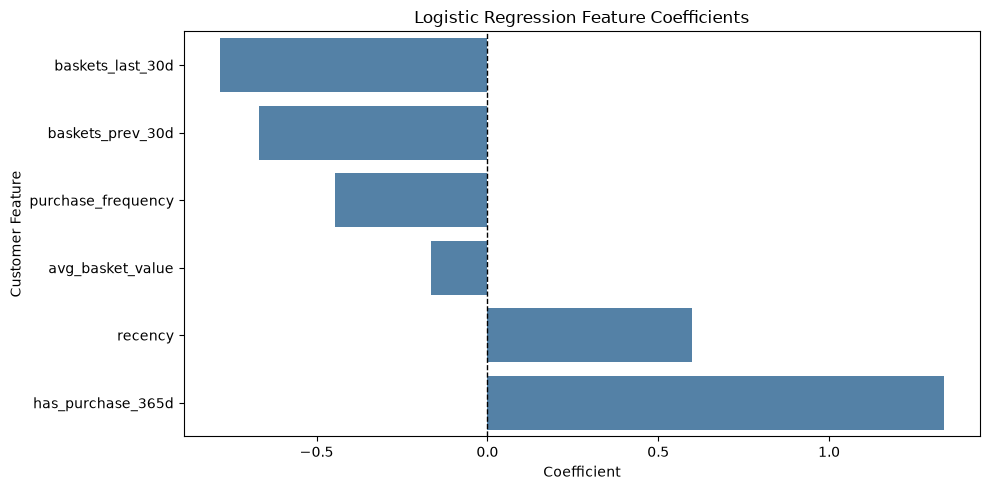

In [20]:

# Sort features for visualization
plot_df = coefficient_df.sort_values("coefficient")

plt.figure(figsize=(10, 5))

sns.barplot(
    data=plot_df,
    x="coefficient",
    y="feature",
    color="steelblue",
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
)

plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Customer Feature")

plt.tight_layout()
plt.show()



## 4.13 Key Findings and Conclusions

### Problem Definition

We developed a binary classification model to predict customer inactivity over the next 90 days.

The target variable was defined as:

- 0: Customer makes at least one purchase.
- 1: Customer makes no purchases.

We used historical customer behavior to create model features.

### Data Preparation

- Training observations: 7,491
- Validation observations: 2,498
- Test observations: 2,499
- Test inactivity rate: 6.96%

We used time-based datasets to reduce data leakage.

### Feature Engineering

We created customer behavior features, including purchase frequency, basket value, recency, and recent shopping activity.

Log Transformation + StandardScaler improved validation Average Precision compared with StandardScaler alone.

### Model Development

We compared Logistic Regression and Random Forest models.

We also tested class weighting and different classification thresholds.

Balanced Logistic Regression achieved the highest validation Average Precision.

Hyperparameter optimization did not improve the selected model.

### Selected Model

- Algorithm: Balanced Logistic Regression
- Regularization: L2
- C: 1.0
- Classification threshold: 0.80
- Preprocessing: Log Transformation + StandardScaler

### Final Test Performance

| Metric | Score |
|---|---:|
| Accuracy | 0.90 |
| Precision | 0.35 |
| Recall | 0.50 |
| F1-Score | 0.41 |
| ROC-AUC | 0.89 |
| Average Precision | 0.35 |

The model correctly identified 87 of 174 inactive customers.

However, it also produced 165 false positive predictions.

### Model Interpretation

Recent purchase activity and purchase frequency were negatively associated with predicted inactivity.

Higher Recency was positively associated with predicted inactivity.

Some coefficients may be difficult to interpret because customer features are correlated.

These relationships do not prove causation.

### Limitations

- The dataset contains a small minority class.
- Some customers appear in multiple historical training snapshots.
- Validation performance was higher than final test performance.
- The selected threshold may not be optimal for every business situation.
- Predicted probabilities may require calibration.
- A new independent test period is needed to confirm future performance.

### Conclusion

Balanced Logistic Regression identified useful patterns in historical customer activity.

The model achieved a test ROC-AUC of 0.89 and Average Precision of 0.35.

However, its final test Recall was only 0.50, so it missed half of the inactive customers.

The model is a useful experimental baseline, but it is not yet validated for production decisions.

The next step is to prepare reusable Python scripts for feature engineering, training, and prediction.


In [21]:
# Create output directories
model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save the trained Pipeline
model_path = model_dir / "churn_logistic_pipeline.joblib"

joblib.dump(final_model, model_path)

# Save prediction configuration
model_metadata = {
    "model_name": "Balanced Logistic Regression",
    "features": feature_columns,
    "threshold": float(final_threshold),
    "observation_days": 365,
    "prediction_days": 90,
    "training_snapshots": TRAIN_SNAPSHOTS,
    "validation_snapshot": VALIDATION_SNAPSHOT,
    "test_snapshot": TEST_SNAPSHOT,
    "status": "experimental",
}

metadata_path = model_dir / "churn_model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(model_metadata, file, indent=4)

print("Model saved:", model_path)
print("Metadata saved:", metadata_path)


Model saved: C:\Users\okand\Desktop\Projects\dunnhumby-retail-intelligence\models\churn_logistic_pipeline.joblib
Metadata saved: C:\Users\okand\Desktop\Projects\dunnhumby-retail-intelligence\models\churn_model_metadata.json



## 4.14 Advanced Machine Learning — LightGBM

We will develop a LightGBM classifier to predict customer inactivity.

Our goals are:

- Learn non-linear relationships between customer features.
- Compare LightGBM with Logistic Regression.
- Evaluate ROC-AUC and Average Precision.
- Use validation data for model selection.

We will not use the final test dataset during model development.


In [23]:
# Validate feature alignment
assert X_train.columns.tolist() == X_val.columns.tolist()

assert "household_key" not in X_train.columns
assert "churn_90d" not in X_train.columns
assert "snapshot_day" not in X_train.columns

In [24]:
# Initialize LightGBM
lgbm_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=-1,
    min_child_samples=40,
    reg_lambda=1.0,
    metric="average_precision",
    random_state=42,
    n_jobs=4,
    verbosity=-1,
)

# Train the model
lgbm_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            first_metric_only=True,
            verbose=False,
        )
    ],
)

# Predict validation probabilities
lgbm_val_proba = lgbm_model.predict_proba(
    X_val
)[:, 1]

# Calculate evaluation metrics
lgbm_results = pd.DataFrame(
    {
        "roc_auc": [
            roc_auc_score(y_val, lgbm_val_proba)
        ],
        "average_precision": [
            average_precision_score(
                y_val, lgbm_val_proba
            )
        ],
    },
    index=["LightGBM"],
)

print("Best Iteration:", lgbm_model.best_iteration_)

display(lgbm_results.round(4))

Best Iteration: 14


c:\Users\okand\Desktop\Projects\dunnhumby-retail-intelligence\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,roc_auc,average_precision
LightGBM,0.90,0.44



## 4.15 LightGBM Hyperparameter Optimization

We will use Optuna to optimize the LightGBM classifier.

Our main objective is to maximize Average Precision.

We will tune model complexity, learning rate, and regularization parameters.

Only training and validation data will be used.

The final test dataset will remain excluded from optimization.


In [28]:
def objective(trial):
    """Optimize LightGBM using validation Average Precision."""

    # Define hyperparameter search space
    params = {
        "objective": "binary",
        "metric": "average_precision",
        "n_estimators": 400,
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.10, log=True
        ),
        "num_leaves": trial.suggest_int(
            "num_leaves", 7, 31
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 3, 7
        ),
        "min_child_samples": trial.suggest_int(
            "min_child_samples", 20, 120
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.01, 10.0, log=True
        ),
        "class_weight": trial.suggest_categorical(
            "class_weight", [None, "balanced"]
        ),
        "random_state": 42,
        "n_jobs": 4,
        "verbosity": -1,
    }

    # Train LightGBM
    model = lgb.LGBMClassifier(**params)

    model.fit(
        X_train,
        y_train,
        eval_X=X_val,
        eval_y=y_val,
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=40,
                first_metric_only=True,
                verbose=False,
            )
        ],
    )

    # Predict validation probabilities
    val_proba = model.predict_proba(X_val)[:, 1]

    # Return optimization metric
    return average_precision_score(y_val, val_proba)

In [29]:

# Show only Optuna warnings and errors
optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

# Create optimization study
lgbm_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

# Run 20 optimization trials
lgbm_study.optimize(
    objective,
    n_trials=20,
    show_progress_bar=True,
)

# Display optimization results
print("Best Validation Average Precision:")
print(round(lgbm_study.best_value, 4))

print("\nBest Hyperparameters:")
for name, value in lgbm_study.best_params.items():
    print(f"{name}: {value}")

# Create trial summary
lgbm_trials = lgbm_study.trials_dataframe()

display(
    lgbm_trials.sort_values(
        "value", ascending=False
    ).head(10)
)


Best trial: 15. Best value: 0.455182: 100%|██████████| 20/20 [00:03<00:00,  5.44it/s]

Best Validation Average Precision:
0.4552

Best Hyperparameters:
learning_rate: 0.010997753818989577
num_leaves: 8
max_depth: 4
min_child_samples: 22
reg_lambda: 0.4433649731254723
class_weight: balanced


,number,value,datetime_start,datetime_complete,duration,params_class_weight,params_learning_rate,params_max_depth,params_min_child_samples,params_num_leaves,params_reg_lambda,system_attrs_tpe:relative_params:0,state
15,15,0.46,2026-11-08 22:08:07.325733,2026-11-08 22:08:07.632104,0 days 00:00:00.306371,balanced,0.01,4,22,8,0.44,"{""class_weight"": ""balanced"", ""learning_rate"": ...",COMPLETE
12,12,0.45,2026-11-08 22:08:06.668701,2026-11-08 22:08:06.870270,0 days 00:00:00.201569,balanced,0.02,3,37,9,0.08,"{""class_weight"": ""balanced"", ""learning_rate"": ...",COMPLETE
8,8,0.45,2026-11-08 22:08:05.948754,2026-11-08 22:08:06.247338,0 days 00:00:00.298584,balanced,0.01,3,52,11,0.15,NaN,COMPLETE
17,17,0.45,2026-11-08 22:08:07.868773,2026-11-08 22:08:08.026071,0 days 00:00:00.157298,balanced,0.03,5,24,7,0.09,"{""class_weight"": ""balanced"", ""learning_rate"": ...",COMPLETE
13,13,0.45,2026-11-08 22:08:06.872269,2026-11-08 22:08:07.117439,0 days 00:00:00.245170,balanced,0.02,3,34,10,0.02,"{""class_weight"": ""balanced"", ""learning_rate"": ...",COMPLETE
18,18,0.45,2026-11-08 22:08:08.028077,2026-11-08 22:08:08.326382,0 days 00:00:00.298305,balanced,0.01,3,27,12,0.59,"{""class_weight"": ""balanced"", ""learning_rate"": ...",COMPLETE
14,14,0.45,2026-11-08 22:08:07.119441,2026-11-08 22:08:07.323349,0 days 00:00:00.203908,balanced,0.02,3,43,8,0.89,"{""class_weight"": ""balanced"", ""learning_rate"": ...",COMPLETE
10,10,0.45,2026-11-08 22:08:06.433217,2026-11-08 22:08:06.554454,0 days 00:00:00.121237,balanced,0.03,3,68,25,0.07,"{""class_weight"": ""balanced"", ""learning_rate"": ...",COMPLETE
9,9,0.45,2026-11-08 22:08:06.247338,2026-11-08 22:08:06.432217,0 days 00:00:00.184879,balanced,0.02,5,34,14,2.55,NaN,COMPLETE
16,16,0.45,2026-11-08 22:08:07.632104,2026-11-08 22:08:07.868773,0 days 00:00:00.236669,balanced,0.02,5,24,14,0.17,"{""class_weight"": ""balanced"", ""learning_rate"": ...",COMPLETE



### 4.16 Hyperparameter Optimization Results

We completed 20 Optuna trials for LightGBM.

The best validation Average Precision was 0.4552.

Logistic Regression achieved a higher validation Average Precision of approximately 0.49.

Therefore, we selected Logistic Regression as our final churn prediction model.

We will save the optimization results for documentation and reproducibility.


In [34]:
# Create output directory
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# Save all Optuna trials
lgbm_trials = lgbm_study.trials_dataframe()

lgbm_trials.to_csv(
    output_dir / "lightgbm_optuna_trials.csv",
    index=False,
)

# Save optimization summary
optimization_summary = {
    "best_trial": lgbm_study.best_trial.number,
    "best_validation_ap": lgbm_study.best_value,
    "best_params": lgbm_study.best_params,
    "n_trials": len(lgbm_study.trials),
    "selected_model": "Logistic Regression",
}

with open(
    output_dir / "lightgbm_optuna_summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        optimization_summary,
        file,
        indent=4,
    )

print("Optuna results saved successfully.")

Optuna results saved successfully.



## 4.17 Model Explainability with SHAP

We will use SHAP to explain our selected Logistic Regression model.

Our goals are:

- Understand global feature importance.
- Analyze how features affect churn predictions.
- Explain predictions for individual customers.
- Visualize SHAP values using summary and waterfall plots.

We will use the existing trained model without retraining it.


In [35]:
# Load selected churn model
churn_pipeline = joblib.load(
    PROJECT_ROOT
    / "models"
    / "churn_logistic_pipeline.joblib"
)

# Display pipeline structure
print("MODEL TYPE")
print(type(churn_pipeline))

print("\nPIPELINE STRUCTURE")
print(churn_pipeline)

print("\nPIPELINE STEPS")
print(list(churn_pipeline.named_steps.keys()))

MODEL TYPE
<class 'sklearn.pipeline.Pipeline'>

PIPELINE STRUCTURE
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['purchase_frequency',
                                                   'avg_basket_value',
                                                   'recency',
                                                   'baskets_last_30d',
                                                   'baskets_prev_30d']),
                                                 ('binary', 'passthrough',
                                                  ['has_purchas


### 4.18 SHAP LinearExplainer

We will use SHAP LinearExplainer to explain our Logistic Regression model.

The model uses six customer features.

We will apply the existing preprocessing pipeline before calculating SHAP values.

SHAP values will explain model predictions in log-odds units.

We will first analyze global feature importance and then individual customer predictions.


In [38]:
# 1. Extract fitted pipeline components
preprocessor = churn_pipeline.named_steps["preprocessing"]
classifier = churn_pipeline.named_steps["classifier"]

# 2. Get feature names from the fitted ColumnTransformer
numeric_features = list(
    preprocessor.transformers_[0][2]
)

binary_features = list(
    preprocessor.transformers_[1][2]
)

feature_names = numeric_features + binary_features

# 3. Select background and explanation data
X_background = X_train.sample(
    n=min(200, len(X_train)),
    random_state=42,
)

X_explain = X_val.sample(
    n=min(500, len(X_val)),
    random_state=42,
)

# 4. Apply the fitted preprocessing pipeline
background_array = preprocessor.transform(X_background)
explain_array = preprocessor.transform(X_explain)

# Convert to dense only if necessary (6 features)
if issparse(background_array):
    background_array = background_array.toarray()

if issparse(explain_array):
    explain_array = explain_array.toarray()

# 5. Create transformed DataFrames
X_background_processed = pd.DataFrame(
    background_array,
    columns=feature_names,
    index=X_background.index,
)

X_explain_processed = pd.DataFrame(
    explain_array,
    columns=feature_names,
    index=X_explain.index,
)

# 6. Validate features
assert classifier.coef_.shape[1] == len(feature_names)
assert X_explain_processed.notna().all().all()

print("Feature Names:", feature_names)
print("Background Shape:", X_background_processed.shape)
print("Explain Shape:", X_explain_processed.shape)

Feature Names: ['purchase_frequency', 'avg_basket_value', 'recency', 'baskets_last_30d', 'baskets_prev_30d', 'has_purchase_365d']
Background Shape: (200, 6)
Explain Shape: (500, 6)


In [39]:

# 1. Initialize SHAP LinearExplainer
explainer = shap.LinearExplainer(
    classifier,
    X_background_processed,
)

# 2. Calculate SHAP values
shap_values = explainer(
    X_explain_processed
)

# 3. Display results
print("SHAP Values Shape:", shap_values.values.shape)

print(
    "Expected Value:",
    round(float(np.mean(shap_values.base_values)), 4)
)

# 4. Check explanation consistency
reconstructed_scores = (
    shap_values.base_values
    + shap_values.values.sum(axis=1)
)

model_scores = classifier.decision_function(
    X_explain_processed
)

assert np.allclose(
    reconstructed_scores,
    model_scores,
    atol=1e-5,
)

print("SHAP Additivity Check: PASSED")


SHAP Values Shape: (500, 6)
Expected Value: -1.9785
SHAP Additivity Check: PASSED


c:\Users\okand\Desktop\Projects\dunnhumby-retail-intelligence\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


GLOBAL SHAP FEATURE IMPORTANCE


,feature,mean_abs_shap
0,baskets_last_30d,0.64
1,baskets_prev_30d,0.56
2,recency,0.46
3,purchase_frequency,0.38
4,avg_basket_value,0.13
5,has_purchase_365d,0.02


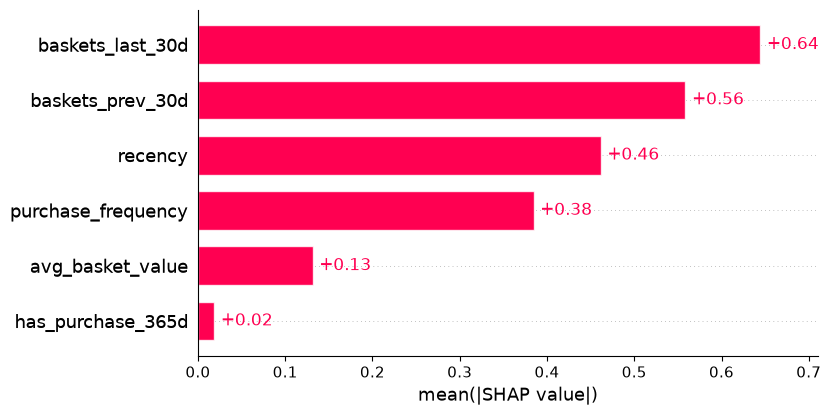

In [40]:

# Calculate mean absolute SHAP values
global_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(
        shap_values.values
    ).mean(axis=0),
})

global_importance = global_importance.sort_values(
    "mean_abs_shap",
    ascending=False,
).reset_index(drop=True)

print("GLOBAL SHAP FEATURE IMPORTANCE")

display(global_importance.round(4))

# Visualize global importance
shap.plots.bar(
    shap_values,
    max_display=6,
)



### 4.19 SHAP Beeswarm Analysis

We will use a SHAP Beeswarm Plot to understand how customer features affect churn predictions.

Each point represents one customer observation.

The horizontal position shows the SHAP value.

The color represents the original feature value.

Positive SHAP values increase the predicted churn log-odds, while negative values decrease them.


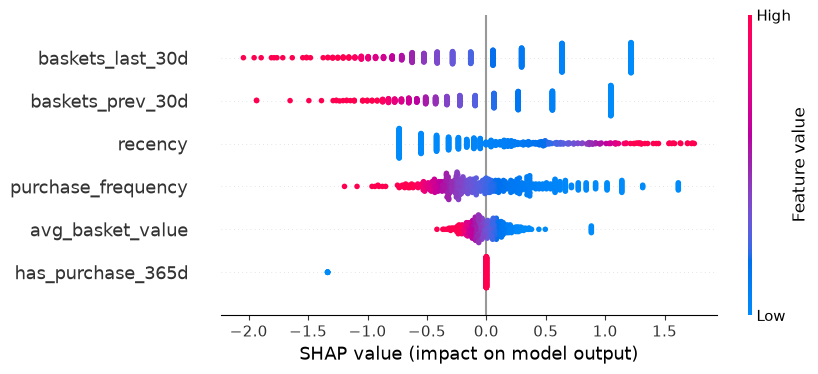

In [41]:

# 1. Create explanations with original feature values
shap_original = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=X_explain[feature_names].to_numpy(),
    feature_names=feature_names,
)

# 2. Validate dimensions
assert shap_original.values.shape == (
    len(X_explain),
    len(feature_names),
)

# 3. Visualize SHAP feature effects
shap.plots.beeswarm(
    shap_original,
    max_display=6,
)



### 4.20 SHAP Waterfall Analysis

We will use Waterfall Plots to explain individual churn predictions.

We will select two customers from the validation sample:

- A customer with a high predicted churn score.
- A customer with a low predicted churn score.

The plots will show how each feature contributes to the final model output.

SHAP values are measured in log-odds units.


In [42]:
# 1. Get predicted churn probabilities
churn_probabilities = churn_pipeline.predict_proba(
    X_explain
)[:, 1]

# 2. Find customers with highest and lowest scores
high_risk_idx = int(np.argmax(churn_probabilities))
low_risk_idx = int(np.argmin(churn_probabilities))

# 3. Create a comparison table
selected_customers = pd.DataFrame({
    "risk_group": ["High Risk", "Low Risk"],
    "row_position": [high_risk_idx, low_risk_idx],
    "churn_score": [
        churn_probabilities[high_risk_idx],
        churn_probabilities[low_risk_idx],
    ],
})

display(selected_customers.round(4))


,risk_group,row_position,churn_score
0,High Risk,361,0.97
1,Low Risk,149,0.00


HIGH-RISK CUSTOMER
Predicted Churn Score: 0.9689


,purchase_frequency,avg_basket_value,recency,baskets_last_30d,baskets_prev_30d,has_purchase_365d
149,1.00,9.99,331,0.00,0.00,1


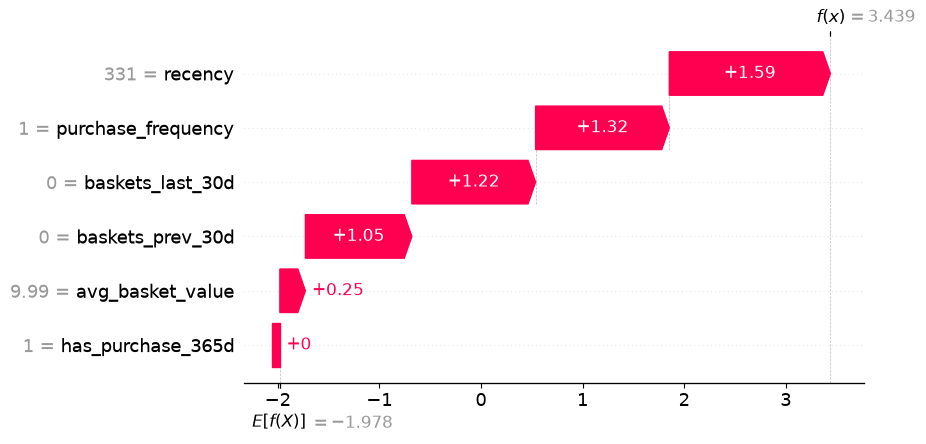

In [43]:

# High-risk customer
print("HIGH-RISK CUSTOMER")
print(
    "Predicted Churn Score:",
    round(float(churn_probabilities[high_risk_idx]), 4)
)

display(
    X_explain.iloc[[high_risk_idx]][feature_names]
)

shap.plots.waterfall(
    shap_original[high_risk_idx],
    max_display=6,
)


LOW-RISK CUSTOMER
Predicted Churn Score: 0.0006


,purchase_frequency,avg_basket_value,recency,baskets_last_30d,baskets_prev_30d,has_purchase_365d
613,660.00,19.14,3,43.00,66.00,1


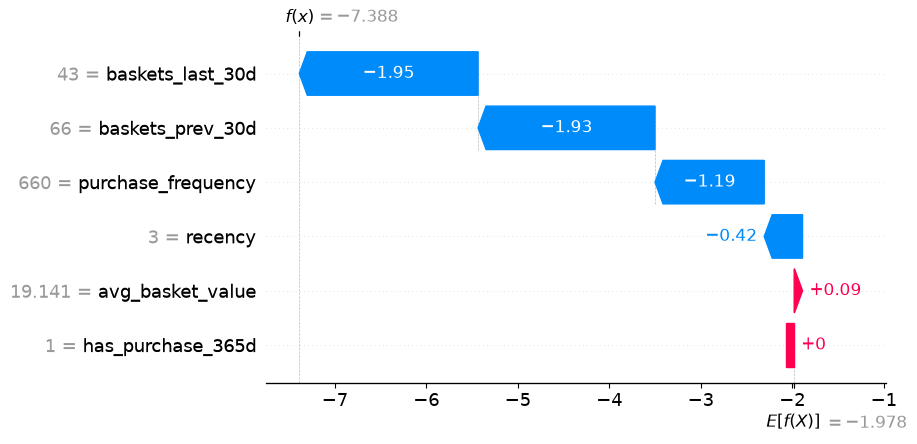

In [44]:

# Low-risk customer
print("LOW-RISK CUSTOMER")
print(
    "Predicted Churn Score:",
    round(float(churn_probabilities[low_risk_idx]), 4)
)

display(
    X_explain.iloc[[low_risk_idx]][feature_names]
)

shap.plots.waterfall(
    shap_original[low_risk_idx],
    max_display=6,
)



### 4.21 Save SHAP Results

We will save the SHAP feature importance results and visualizations.

These files will support model documentation and future reporting.

The explanations show how customer features contribute to the Logistic Regression model's churn scores.


In [45]:
# 1. Create output directory
shap_dir = PROJECT_ROOT / "reports" / "figures" / "shap"
shap_dir.mkdir(parents=True, exist_ok=True)

# 2. Save Global Feature Importance
global_importance.to_csv(
    shap_dir / "shap_global_importance.csv",
    index=False,
)

# 3. Save Global SHAP Bar Plot
shap.plots.bar(
    shap_values,
    max_display=6,
    show=False,
)

plt.savefig(
    shap_dir / "shap_global_bar.png",
    dpi=150,
    bbox_inches="tight",
)
plt.close()

# 4. Save Beeswarm Plot
shap.plots.beeswarm(
    shap_original,
    max_display=6,
    show=False,
)

plt.savefig(
    shap_dir / "shap_beeswarm.png",
    dpi=150,
    bbox_inches="tight",
)
plt.close()

# 5. Save High-Risk Waterfall Plot
shap.plots.waterfall(
    shap_original[high_risk_idx],
    max_display=6,
    show=False,
)

plt.savefig(
    shap_dir / "shap_high_risk.png",
    dpi=150,
    bbox_inches="tight",
)
plt.close()

# 6. Save Low-Risk Waterfall Plot
shap.plots.waterfall(
    shap_original[low_risk_idx],
    max_display=6,
    show=False,
)

plt.savefig(
    shap_dir / "shap_low_risk.png",
    dpi=150,
    bbox_inches="tight",
)
plt.close()

# 7. Verify saved files
for file_path in sorted(shap_dir.iterdir()):
    print(file_path.name)

print("\nSHAP results saved successfully.")

shap_beeswarm.png
shap_global_bar.png
shap_global_importance.csv
shap_high_risk.png
shap_low_risk.png

SHAP results saved successfully.



### 4.22 SHAP Analysis Conclusions

SHAP analysis helped us understand the predictions of our Logistic Regression model.

**Key Findings**

- Recent shopping activity is the most important factor in the model.
- Customers with fewer recent purchases generally receive higher churn scores.
- Higher recency values increase the predicted churn score.
- Purchase frequency also has a strong effect on model predictions.
- Average basket value has a smaller contribution.

**Local Explanations**

The high-risk customer had very low purchase activity and a long period of inactivity.

The low-risk customer had frequent purchases and recent shopping activity.

**Conclusion**

SHAP results are consistent with our earlier feature analysis.

The model mainly uses customer purchase activity and recency to identify churn risk.

These explanations describe model behavior, not causal relationships.
